# 09 The demo

The project in one notebook. It doesn't calculate anything again: it loads what 01 to 08 saved and shows it.
At the end the live part: pick any test wafer and the model says what's wrong with it.

In [4]:
import csv

import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import recall_score

import wafer

# only loading here, nothing gets trained again
split = np.load("output/split.npz")
f = np.load("output/features.npz")
p = np.load("output/test_predictions.npz")
forest = joblib.load("output/forest.joblib")
forest.set_params(n_jobs=1)   # one wafer at a time

maps_train, y_train = split["maps_train"], split["y_train"]
maps_test, y_test = split["maps_test"], split["y_test"]

## 1. The problem

A wafer is a disc with chips on it. After testing, every chip passed or failed. The failed chips make a pattern, and
the pattern points at the cause. These are the 8 basic ones.

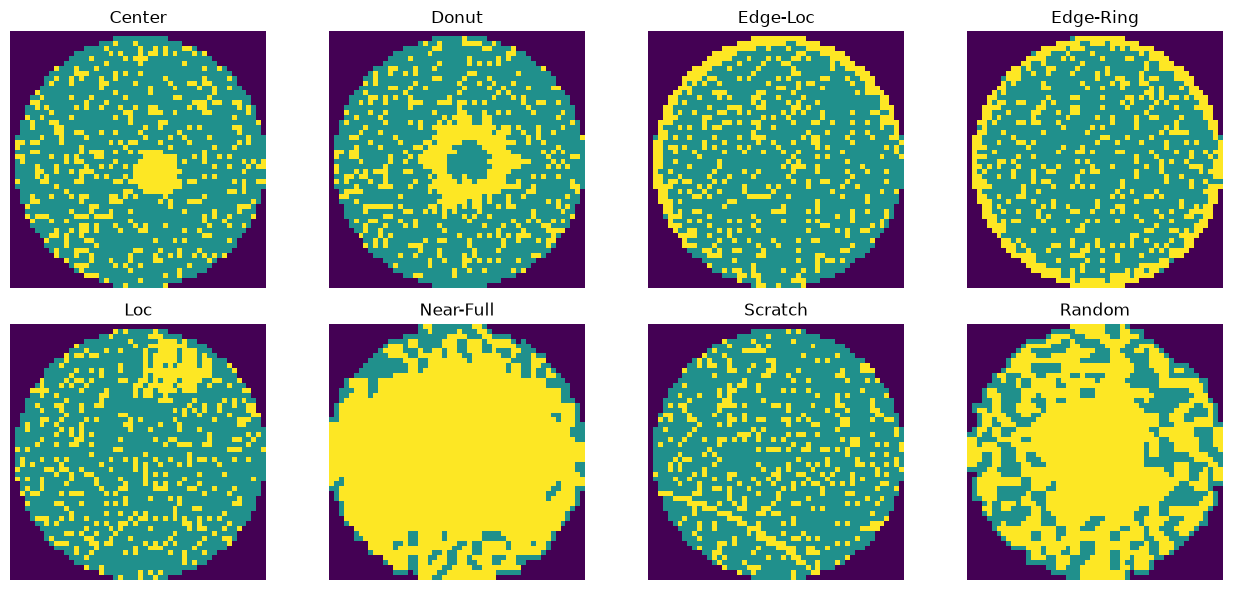

In [5]:
plt.figure(figsize=(13, 6))
for i in range(8):
    only_this = np.zeros(8, dtype=int)
    only_this[i] = 1
    first = np.where((y_train == only_this).all(axis=1))[0][0] # same trick as in 07, first wafer with only this defect
    plt.subplot(2, 4, i + 1)
    plt.imshow(maps_train[first])
    plt.title(wafer.DEFECTS[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. The data and the split

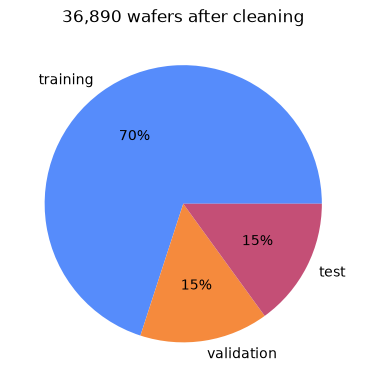

In [6]:
sizes = [len(maps_train), len(split["maps_val"]), len(maps_test)]
plt.figure(figsize=(4.5, 4.5))
plt.pie(sizes, labels=["training", "validation", "test"], autopct="%1.0f%%") # autopct writes the % in the slices
plt.title(f"{sum(sizes):,} wafers after cleaning")
plt.show()

## 3. From a picture to 14 numbers

The model never sees the picture, only the share failed on the whole wafer, in 5 rings and in 8 slices.

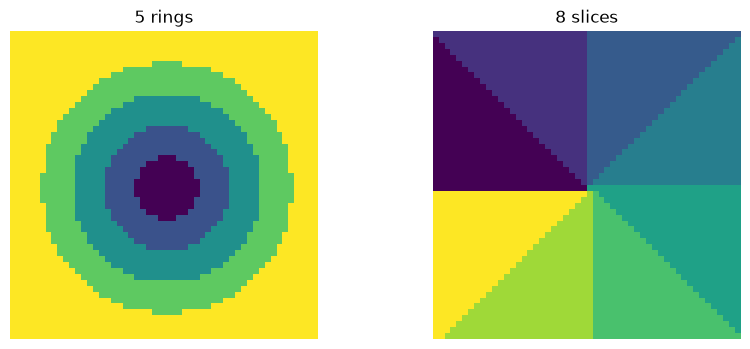

In [7]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(wafer.RING)
plt.title("5 rings")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(wafer.SLICE)
plt.title("8 slices")
plt.axis("off")
plt.show()

## 4. How well it works

Recall per defect on the test part, the forest next to the baseline.

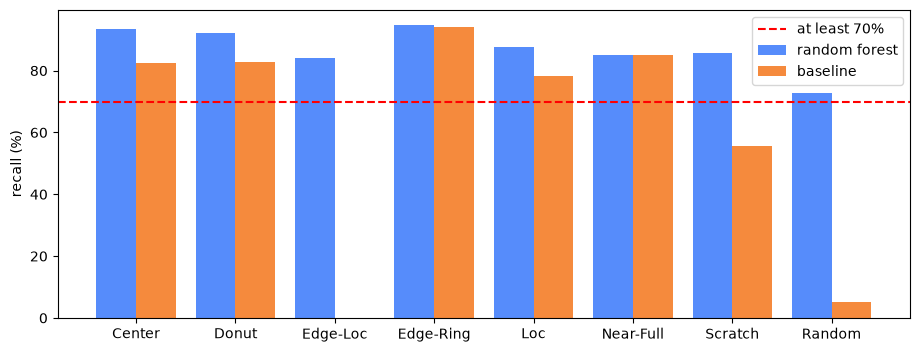

In [8]:
recall = recall_score(p["y_test"], p["y_pred"], average=None)
recall_base = recall_score(p["y_test"], p["y_base"], average=None)
x = np.arange(8) # 0 to 7, one spot per defect

plt.figure(figsize=(11, 4))
# 2 bars per defect, one moved a bit left and one a bit right
plt.bar(x - 0.2, recall * 100, 0.4, label="random forest")
plt.bar(x + 0.2, recall_base * 100, 0.4, label="baseline")
plt.axhline(70, color="red", linestyle="--", label="at least 70%")
plt.xticks(x, wafer.DEFECTS)
plt.ylabel("recall (%)")
plt.legend()
plt.show()

## 5. Did it do what I promised?

In [9]:
# DictReader gives every row as a dictionary, row["No"] etc
with open("output/validation.csv", encoding="utf-8") as file:
    for row in csv.DictReader(file):
        print(f"{row['No']}: {row['Pass/Fail']} ({row['What']})")

T1: Pass (8 answers per wafer, only 0 and 1)
T2: Pass (all zeros is called Normal)
T3: Pass (no copies left)
T4: Pass (no value 3 left)
T5: Pass (all 38 types in every part)
V1: Pass (no map in two split sets)
QC-01: Pass (recall at least 70% on every defect)
QC-02: Pass (all 8 right on at least 60%)
QC-03: Pass (precision at least 60% on every defect)
QC-04: Fail (higher F1 than the baseline on every defect)
QC-05: Fail (my wafers at most 15 points lower)
QC-08: Pass (one wafer under 50 ms)


## 6. Live: classify one wafer

The bars are the share of trees that said yes per defect. Above the red line means yes. Change the number to try
another test wafer.

Model says: Center + Loc
True label: Center + Loc


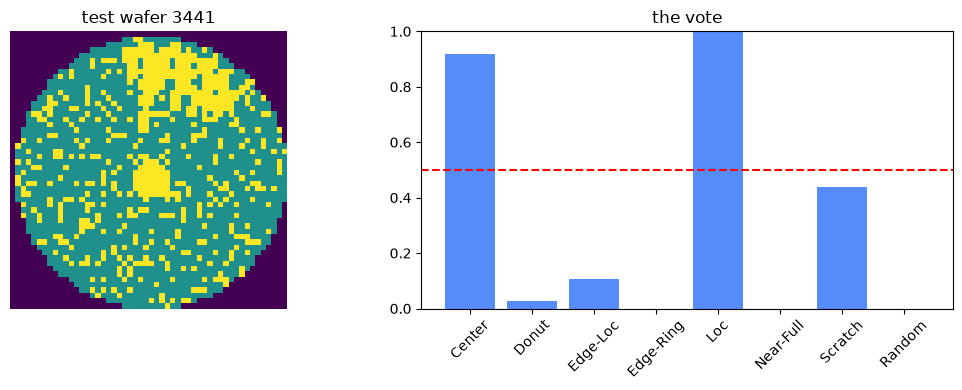

In [14]:
def show(number):
    numbers = wafer.features(maps_test[number])
    said = forest.predict([numbers])[0] # table of 1 row in, [0] to get that one answer out

    print("Model says:", wafer.label_name(said))
    print("True label:", wafer.label_name(y_test[number]))

    # predict_proba gives per defect [share no, share yes]; I keep the yes
    votes = []
    for chances in forest.predict_proba([numbers]):
        votes.append(chances[0][1]) # [0] the wafer, [1] the yes part

    plt.figure(figsize=(11, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(maps_test[number])
    plt.title(f"test wafer {number}")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.bar(wafer.DEFECTS, votes)
    plt.axhline(0.5, color="red", linestyle="--") # over half the trees = yes
    plt.xticks(rotation=45)
    plt.ylim(0, 1)
    plt.title("the vote")
    plt.tight_layout()
    plt.show()


number = 3441   # any test wafer, from 0 to len(maps_test) - 1
show(number)